# Soil Analytics – Data Preprocessing

In [1]:
import pandas as pd, numpy as np, os, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import warnings; warnings.filterwarnings("ignore")

DATA = "."
PROC = "processed"
MODELS = "../models"
os.makedirs(PROC, exist_ok=True)
os.makedirs(MODELS, exist_ok=True)

crop = pd.read_csv(f"{DATA}/Crop_recommendation.csv")
fert = pd.read_csv(f"{DATA}/Fertilizer_Prediction.csv")
print(crop.shape, fert.shape)

(2200, 8) (99, 9)


## Inspect

In [2]:
for n, d in [("CROP", crop), ("FERT", fert)]:
    print(f"--- {n} ---")
    print(d.dtypes.to_string())
    print("nulls:", d.isna().sum().sum(), "| duplicates:", d.duplicated().sum())
    display(d.describe().T)
print(crop["label"].value_counts().describe())
print(fert["Fertilizer Name"].value_counts())

--- CROP ---
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label              str
nulls: 0 | duplicates: 0


,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


--- FERT ---
Temparature        int64
Humidity           int64
Moisture           int64
Soil Type            str
Crop Type            str
Nitrogen           int64
Potassium          int64
Phosphorous        int64
Fertilizer Name      str
nulls: 0 | duplicates: 0


,count,mean,std,min,25%,50%,75%,max
Temparature,99.0,30.282828,3.502304,25.0,28.0,30.0,33.0,38.0
Humidity,99.0,59.151515,5.840331,50.0,54.0,60.0,64.0,72.0
Moisture,99.0,43.181818,11.271568,25.0,34.0,41.0,50.5,65.0
Nitrogen,99.0,18.909091,11.599693,4.0,10.0,13.0,24.0,42.0
Potassium,99.0,3.383838,5.814667,0.0,0.0,0.0,7.5,19.0
Phosphorous,99.0,18.606061,13.476978,0.0,9.0,19.0,30.0,42.0


count     22.0
mean     100.0
std        0.0
min      100.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
Name: count, dtype: float64
Fertilizer Name
Urea        22
DAP         18
28-28       17
14-35-14    14
20-20       14
17-17-17     7
10-26-26     7
Name: count, dtype: int64


## Clean

In [3]:
crop.columns = crop.columns.str.strip()
fert.columns = fert.columns.str.strip().str.replace("Temparature", "Temperature").str.replace("Phosphorous", "Phosphorus")

crop["label"] = crop["label"].astype(str).str.strip().str.lower()
for c in ["Soil Type", "Crop Type", "Fertilizer Name"]:
    fert[c] = fert[c].astype(str).str.strip()

crop = crop.drop_duplicates().reset_index(drop=True)
fert = fert.drop_duplicates().reset_index(drop=True)

assert crop["ph"].between(0, 14).all() and crop["humidity"].between(0, 100).all()
assert (crop[["N", "P", "K", "rainfall"]] >= 0).all().all()
print(crop.shape, fert.shape)

(2200, 8) (99, 9)


## Outliers

N                0
P              138
K              200
temperature     86
humidity        30
ph              57
rainfall       100
dtype: int64


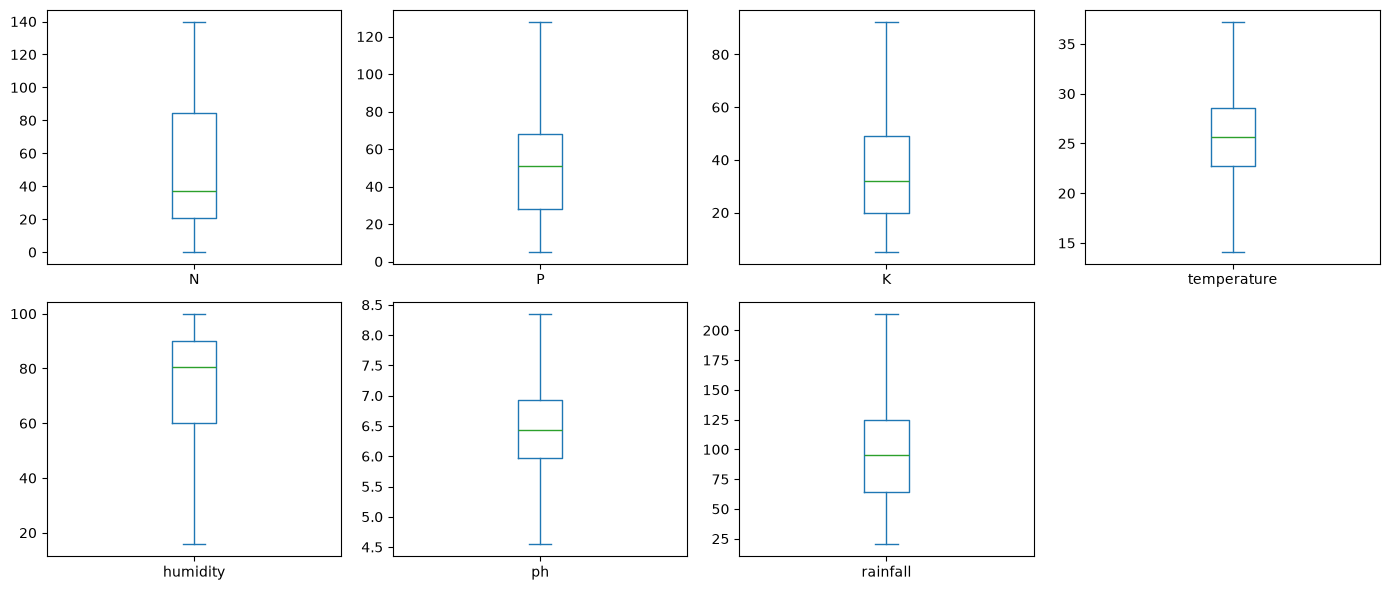

In [4]:
num_c = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
q1, q3 = crop[num_c].quantile(.25), crop[num_c].quantile(.75)
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(((crop[num_c] < lo) | (crop[num_c] > hi)).sum())
crop[num_c] = crop[num_c].clip(lo, hi, axis=1)
crop[num_c].plot(kind="box", subplots=True, layout=(2, 4), figsize=(14, 6))
plt.tight_layout()
plt.show()

## EDA

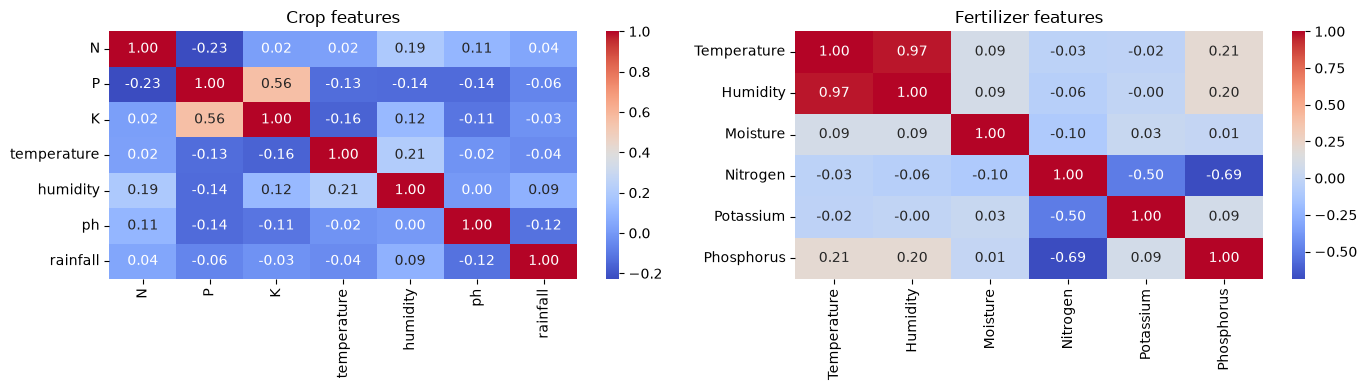

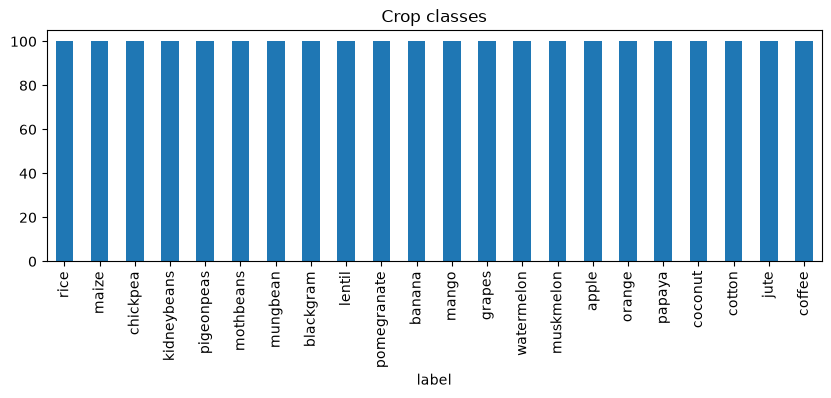

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(crop[num_c].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[0])
ax[0].set_title("Crop features")
sns.heatmap(fert.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1])
ax[1].set_title("Fertilizer features")
plt.tight_layout()
plt.show()
crop["label"].value_counts().plot(kind="bar", figsize=(10, 3), title="Crop classes")
plt.show()

## Crop: encode, split, scale

In [6]:
Xc = crop[num_c]
le_crop = LabelEncoder()
yc = le_crop.fit_transform(crop["label"])
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=.2, stratify=yc, random_state=42)

crop_pre = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
Xc_tr_s = crop_pre.fit_transform(Xc_tr)
Xc_te_s = crop_pre.transform(Xc_te)
print(Xc_tr_s.shape, Xc_te_s.shape)

(1760, 7) (440, 7)


## Fertilizer: encode, split, scale

In [7]:
num_f = ["Temperature", "Humidity", "Moisture", "Nitrogen", "Potassium", "Phosphorus"]
cat_f = ["Soil Type", "Crop Type"]
Xf = fert[num_f + cat_f]
le_fert = LabelEncoder()
yf = le_fert.fit_transform(fert["Fertilizer Name"])
strat = yf if pd.Series(yf).value_counts().min() >= 2 else None
Xf_tr, Xf_te, yf_tr, yf_te = train_test_split(Xf, yf, test_size=.2, stratify=strat, random_state=42)

fert_pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_f),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_f)])
Xf_tr_p = fert_pre.fit_transform(Xf_tr)
Xf_te_p = fert_pre.transform(Xf_te)
print(Xf_tr_p.shape, Xf_te_p.shape)

(79, 22) (20, 22)


## Save

In [8]:
crop.to_csv(f"{PROC}/crop_clean.csv", index=False)
fert.to_csv(f"{PROC}/fert_clean.csv", index=False)
joblib.dump(crop_pre, f"{MODELS}/crop_preprocessor.pkl")
joblib.dump(le_crop, f"{MODELS}/crop_label_encoder.pkl")
joblib.dump(fert_pre, f"{MODELS}/fert_preprocessor.pkl")
joblib.dump(le_fert, f"{MODELS}/fert_label_encoder.pkl")
print(sorted(os.listdir(MODELS)))

['crop_label_encoder.pkl', 'crop_model.pkl', 'crop_preprocessor.pkl', 'fert_label_encoder.pkl', 'fert_model.pkl', 'fert_preprocessor.pkl']
